In [1]:
!pip -q install torch numpy matplotlib

In [2]:
import re, json, os, unicodedata, urllib.request, collections, datetime
import numpy as np, torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(0); np.random.seed(0)
plt.rcParams['figure.dpi'] = 110

In [3]:
URL = 'https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt'
FALLBACK = [
    'Wiatr niósł zapach lasu przez otwarte okno.',
    'Rzeka płynęła spokojnie wśród zielonych wzgórz.',
    'Dzieci bawiły się na łące pełnej kwiatów.',
    'Stary zegar wybił północ w cichym domu.',
    'Ptaki śpiewały o świcie na gałęziach drzew.',
    'Deszcz padał miarowo na dachy miasteczka.',
    'Kot przeciągnął się leniwie w promieniach słońca.',
    'Podróżnik szedł długą drogą ku odległym górom.',
]
try:
    surowy = urllib.request.urlopen(URL, timeout=30).read().decode('utf-8')   # odczyt jako UTF-8
    ZRODLO = 'Wolne Lektury — B. Prus, „Lalka”, tom I (TXT)'
    TRYB_OFFLINE = False
except Exception as e:
    print('Brak dostępu do sieci / błąd pobierania:', e)
    surowy = '\n'.join(FALLBACK * 400)
    ZRODLO = 'tekst zapasowy (offline) — NIE do sprawozdania'
    TRYB_OFFLINE = True
print('Źródło:', ZRODLO)
print('Długość surowego tekstu:', len(surowy), 'znaków')

Źródło: Wolne Lektury — B. Prus, „Lalka”, tom I (TXT)
Długość surowego tekstu: 784082 znaków


In [4]:
print('--- POCZĄTEK ---'); print(repr(surowy[:500]))
sr = len(surowy)//2
print('\n--- ŚRODEK ---');   print(repr(surowy[sr:sr+300]))
print('\n--- KONIEC ---');   print(repr(surowy[-700:]))
print('\nZnaki spoza ASCII (z liczebnością):')
print(collections.Counter(c for c in surowy if ord(c) > 127).most_common())

--- POCZĄTEK ---
'Bolesław Prus\r\n\r\nLalka\r\n\r\nISBN 978-83-288-2673-1\r\n\r\n\r\n\r\n\r\n\r\nTom I\r\n\r\n\r\n\r\nI. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?\r\n\r\nW początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorąco interesowała się przyszłością galanteryjnego sklepu pod firmą J. Mincel i S. Wokulski.\r\n\r\nW renomowanej jadłodajni, gdzie '

--- ŚRODEK ---
'Belwederskiego ogrodu, pod sztachetami od strony szpitala, na ulicach najmniej uczęszczanych, nawet na zagrodzonych ścieżkach, wszędzie było pełno i wesoło. Im więcej ciemniało w naturze, tym gęściej i hałaśliwiej robiło się między ludźmi.\r\n\r\n„Zaczyna mi już braknąć miejsca na świecie!…” — szepnął.\r'

--- KONIEC ---
'wnych.\r\nWykorzystując zasoby z Wolnych Lektur, należy pamiętać o zapisach licencji oraz zasadach, któ

In [5]:
log_czyszczenia = []
def krok(opis, przed, po):
    log_czyszczenia.append((opis, przed - po))
    print(f'{opis:<55} usunięto/zmieniono: {przed - po:>7} znaków')

t = surowy
n0 = len(t)
t = unicodedata.normalize('NFC', t.lstrip('\ufeff'))
krok('normalizacja NFC (+ usunięcie BOM)', n0, len(t))

n0 = len(t); t = t.replace('\r\n', '\n').replace('\r', '\n')
krok('końce linii \\r\\n -> \\n', n0, len(t))

n0 = len(t); t = re.sub(r'<[^>]+>', '', t)
krok('znaczniki HTML', n0, len(t))

# stopka Wolnych Lektur: "-----\nTa lektura, podobnie jak tysiące innych, dostępna jest na stronie wolnelektury.pl ..."
n0 = len(t)
idx = t.rfind('Ta lektura, podobnie jak tysiące innych')
if idx != -1:
    sep = t.rfind('-----', 0, idx)
    t = t[: sep if (sep != -1 and idx - sep < 20) else idx]
krok('stopka serwisu Wolne Lektury', n0, len(t))

n0 = len(t)
t = '\n'.join(l for l in t.split('\n') if 'wolnelektury.pl' not in l)
krok('linie z adresem wolnelektury.pl', n0, len(t))

n0 = len(t); t = re.sub(r'[ \t]+', ' ', t); t = re.sub(r' ?\n ?', '\n', t)
krok('wielokrotne spacje / spacje przy końcu linii', n0, len(t))

n0 = len(t); t = re.sub(r'\n{3,}', '\n\n', t).strip() + '\n'
krok('nadmiar pustych linii', n0, len(t))

tekst = t
print('\nDługość po czyszczeniu:', len(tekst), 'znaków (przed:', len(surowy), ')')

# kontrola powielonych dokumentów/akapitów
akapity = [a.strip() for a in tekst.split('\n') if len(a.strip()) > 40]
dup = [a for a, c in collections.Counter(akapity).items() if c > 1]
print('Akapity dłuższe niż 40 znaków:', len(akapity), '| powielone:', len(dup))
if dup: print('Przykład powtórzenia:', repr(dup[0][:100]))

FRAGMENT = tekst[1500:1900] if len(tekst) > 2500 else tekst[:400]
print('\nFragment po oczyszczeniu:\n', FRAGMENT)

normalizacja NFC (+ usunięcie BOM)                      usunięto/zmieniono:       0 znaków
końce linii \r\n -> \n                                  usunięto/zmieniono:    9851 znaków
znaczniki HTML                                          usunięto/zmieniono:       0 znaków
stopka serwisu Wolne Lektury                            usunięto/zmieniono:    1532 znaków
linie z adresem wolnelektury.pl                         usunięto/zmieniono:       0 znaków
wielokrotne spacje / spacje przy końcu linii            usunięto/zmieniono:       0 znaków
nadmiar pustych linii                                   usunięto/zmieniono:      66 znaków

Długość po czyszczeniu: 772633 znaków (przed: 784082 )
Akapity dłuższe niż 40 znaków: 4064 | powielone: 0

Fragment po oczyszczeniu:
 ił pan Deklewski — musi skończyć człowiek, który nie pilnuje się jednego fachu i nie umie uszanować darów łaskawej fortuny. — Zaś radca Węgrowicz, po każdej również głębokiej sentencji swego przyjaciela, dodawał:

— Wariat! wari

In [6]:
PROP = (0.8, 0.1, 0.1)

def granica(t, p):
    i = int(len(t) * p)
    j = t.find('\n', i)
    return j + 1 if j != -1 else i

a = granica(tekst, PROP[0])
b = granica(tekst, PROP[0] + PROP[1])
czesci = {'train': tekst[:a], 'val': tekst[a:b], 'test': tekst[b:]}
NAZWY = ['train', 'val', 'test']

assert ''.join(czesci[n] for n in NAZWY) == tekst          # rozłączne i ciągłe
for n in NAZWY:
    print(f'{n:<6} znaków: {len(czesci[n]):>8}  ({100*len(czesci[n])/len(tekst):5.2f} %)  różnych znaków: {len(set(czesci[n]))}')
print('Granice podziału (indeksy w oczyszczonym tekście):', a, b)

train  znaków:   618150  (80.01 %)  różnych znaków: 101
val    znaków:    77475  (10.03 %)  różnych znaków: 74
test   znaków:    77008  ( 9.97 %)  różnych znaków: 81
Granice podziału (indeksy w oczyszczonym tekście): 618150 695625


In [7]:
UNK = '\ufffd'
assert UNK not in czesci['train']
znaki = [UNK] + sorted(set(czesci['train']))
stoi = {z: i for i, z in enumerate(znaki)}
itos = {i: z for z, i in stoi.items()}
V = len(znaki)

def enc(s):  return [stoi.get(c, 0) for c in s]        # nieznany znak -> 0
def dec(ids): return ''.join(itos[int(i)] for i in ids)

print('Rozmiar słownika V (z <unk>):', V)
print('Znaki:', repr(''.join(znaki)))

# test kodowania i dekodowania
frag = czesci['train'][:1000]
assert dec(enc(frag)) == frag
print('Test enc/dec na 1000 znakach treningu: OK')

dane = {n: np.array(enc(czesci[n]), dtype=np.int64) for n in NAZWY}

# znaki spoza słownika w walidacji / teście
oov = {}
for n in NAZWY:
    c = collections.Counter(ch for ch in czesci[n] if ch not in stoi)
    oov[n] = c
    print(f'{n:<6} znaki spoza słownika: {sum(c.values())} wystąpień, {len(c)} różnych', dict(c) if c else '')

# test dokładnego odtworzenia na fragmencie pokrytym przez słownik
for n in ['val', 'test']:
    pokryty = ''.join(ch for ch in czesci[n] if ch in stoi)
    assert dec(enc(pokryty)) == pokryty
print('Test enc/dec na fragmentach val/test pokrytych przez słownik: OK')
print('Reguła: znak spoza słownika -> ID 0 (', repr(UNK), '), dekodowanie zwraca ten symbol.')

Rozmiar słownika V (z <unk>): 102
Znaki: "�\n !'()*,-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz«»ÓàçéóöüąćęŁłńŚśŹźŻż–—”„…"
Test enc/dec na 1000 znakach treningu: OK
train  znaki spoza słownika: 0 wystąpień, 0 różnych 
val    znaki spoza słownika: 0 wystąpień, 0 różnych 
test   znaki spoza słownika: 0 wystąpień, 0 różnych 
Test enc/dec na fragmentach val/test pokrytych przez słownik: OK
Reguła: znak spoza słownika -> ID 0 ( '�' ), dekodowanie zwraca ten symbol.


In [8]:
class DatasetZnakowy(Dataset):
    def __init__(self, dane, sekw):
        self.dane = dane; self.sekw = sekw
    def __len__(self):
        return max(0, len(self.dane) - self.sekw)
    def __getitem__(self, i):
        if not 0 <= i < len(self):
            raise IndexError(i)
        x = self.dane[i:i+self.sekw]
        y = self.dane[i+1:i+self.sekw+1]     # przesunięcie o 1
        return torch.tensor(x), torch.tensor(y)

SEKW = 40
BATCH = 32

def zbuduj(sekw):
    ds = {n: DatasetZnakowy(dane[n], sekw) for n in NAZWY}
    dl = {n: DataLoader(ds[n], batch_size=BATCH,
                        shuffle=(n == 'train'), drop_last=(n == 'train')) for n in NAZWY}
    return ds, dl

datasety, loadery = zbuduj(SEKW)
for n in NAZWY:
    print(f'{n:<6} par: {len(datasety[n]):>7}  batchy: {len(loadery[n]):>6}')

train  par:  618110  batchy:  19315
val    par:   77435  batchy:   2420
test   par:   76968  batchy:   2406


In [9]:
wiersze = []
for n in NAZWY:
    wiersze.append(dict(zbior=n, znaki=len(czesci[n]), udzial=100*len(czesci[n])/len(tekst),
                        rozne=len(set(czesci[n])), pary=len(datasety[n]), batche=len(loadery[n])))
print(f'{"zbiór":<7}{"znaki":>10}{"udział %":>10}{"różne zn.":>11}{"pary":>10}{"batche":>9}')
for w in wiersze:
    print(f'{w["zbior"]:<7}{w["znaki"]:>10}{w["udzial"]:>10.2f}{w["rozne"]:>11}{w["pary"]:>10}{w["batche"]:>9}')
print(f'\nSEKW={SEKW}, batch_size={BATCH}; train: shuffle=True, drop_last=True; val/test: shuffle=False, drop_last=False; krok okna = 1')
print('Liczba dokumentów w każdym zbiorze: 1 (jeden długi tekst, podział na fragmenty ciągłe)')

zbiór       znaki  udział %  różne zn.      pary   batche
train      618150     80.01        101    618110    19315
val         77475     10.03         74     77435     2420
test        77008      9.97         81     76968     2406

SEKW=40, batch_size=32; train: shuffle=True, drop_last=True; val/test: shuffle=False, drop_last=False; krok okna = 1
Liczba dokumentów w każdym zbiorze: 1 (jeden długi tekst, podział na fragmenty ciągłe)


In [10]:
kontrola = {}
IDX = 123
for n in NAZWY:
    xb, yb = next(iter(loadery[n]))
    assert tuple(xb.shape) == tuple(yb.shape) == (xb.shape[0], SEKW)
    assert 'int64' in str(xb.dtype) and 'int64' in str(yb.dtype)
    assert int(xb.min()) >= 0 and int(xb.max()) < V and int(yb.min()) >= 0 and int(yb.max()) < V
    assert bool((xb[:, 1:] == yb[:, :-1]).all())

    # para o znanym indeksie względem tekstu źródłowego
    i = min(IDX, len(datasety[n]) - 1)
    x, y = datasety[n][i]
    zrodlo = czesci[n]
    assert x.tolist() == enc(zrodlo[i:i+SEKW])
    assert y.tolist() == enc(zrodlo[i+1:i+SEKW+1])
    wej, cel = dec(x.tolist()), dec(y.tolist())
    assert wej[1:] == cel[:-1]
    if not any(ch not in stoi for ch in zrodlo[i:i+SEKW+1]):
        assert wej == zrodlo[i:i+SEKW] and cel == zrodlo[i+1:i+SEKW+1]
    ostatni = zrodlo[i+SEKW]                      # ostatni znak celu sprawdzony bezpośrednio w tekście
    assert cel[-1] == ostatni or ostatni not in stoi

    kontrola[n] = dict(shape=tuple(xb.shape), dtype=str(xb.dtype), idmin=int(xb.min()), idmax=int(xb.max()),
                       i=i, wej=wej, cel=cel, ostatni=ostatni)
    print(f'[{n}] batch X/Y: {tuple(xb.shape)} / {tuple(yb.shape)}, dtype {xb.dtype}, ID {int(xb.min())}..{int(xb.max())} (V={V})')
    print(f'   para i={i}')
    print('   wejście:', repr(wej))
    print('   cel    :', repr(cel))
    print('   ostatni znak celu w tekście źródłowym:', repr(ostatni))
print('\nWszystkie kontrole przeszły.')

[train] batch X/Y: (32, 40) / (32, 40), dtype torch.int64, ID 1..101 (V=102)
   para i=123
   wejście: 'oczątkach roku 1878, kiedy świat polityc'
   cel    : 'czątkach roku 1878, kiedy świat politycz'
   ostatni znak celu w tekście źródłowym: 'z'
[val] batch X/Y: (32, 40) / (32, 40), dtype torch.int64, ID 1..98 (V=102)
   para i=123
   wejście: ', a oni myślą i pewnie mówią: ot, patrza'
   cel    : ' a oni myślą i pewnie mówią: ot, patrzaj'
   ostatni znak celu w tekście źródłowym: 'j'
[test] batch X/Y: (32, 40) / (32, 40), dtype torch.int64, ID 1..101 (V=102)
   para i=123
   wejście: 'Mówiłam mu właśnie o Żydach, a on prosi '
   cel    : 'ówiłam mu właśnie o Żydach, a on prosi c'
   ostatni znak celu w tekście źródłowym: 'c'

Wszystkie kontrole przeszły.


  SEKW    train pary  train batche      val pary    val batche     test pary   test batche
    20        618130         19316         77455          2421         76988          2406
    40        618110         19315         77435          2420         76968          2406
    80        618070         19314         77395          2419         76928          2404
   160        617990         19312         77315          2417         76848          2402


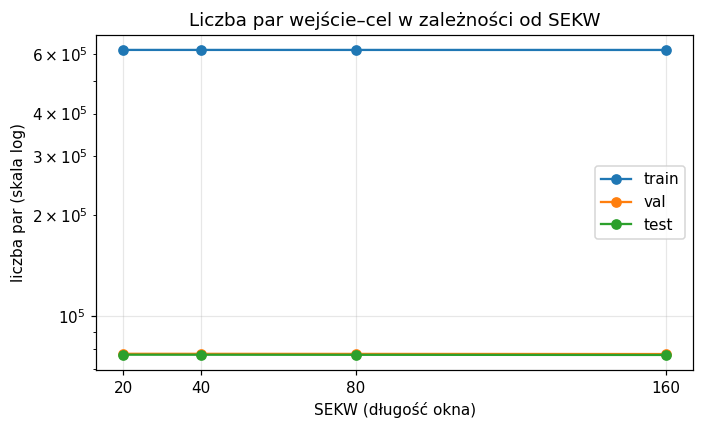

In [11]:
SEKW_LISTA = [20, 40, 80, 160]
pary = {n: [] for n in NAZWY}
batche_sekw = {n: [] for n in NAZWY}
for s in SEKW_LISTA:
    ds_s, dl_s = zbuduj(s)
    for n in NAZWY:
        wzor = max(0, len(czesci[n]) - s)
        assert len(ds_s[n]) == wzor
        pary[n].append(len(ds_s[n])); batche_sekw[n].append(len(dl_s[n]))

print(f'{"SEKW":>6}' + ''.join(f'{n+" pary":>14}{n+" batche":>14}' for n in NAZWY))
for k, s in enumerate(SEKW_LISTA):
    print(f'{s:>6}' + ''.join(f'{pary[n][k]:>14}{batche_sekw[n][k]:>14}' for n in NAZWY))

fig, ax = plt.subplots(figsize=(6.5, 4))
for n in NAZWY:
    ax.plot(SEKW_LISTA, pary[n], marker='o', label=n)
ax.set_yscale('log'); ax.set_xlabel('SEKW (długość okna)'); ax.set_ylabel('liczba par (skala log)')
ax.set_title('Liczba par wejście–cel w zależności od SEKW'); ax.set_xticks(SEKW_LISTA); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig('fig_pary_sekw.png'); plt.show()

    ␣     93892  15.19 %
    a     44134   7.14 %
    i     42211   6.83 %
    e     37055   5.99 %
    o     34046   5.51 %
    z     27753   4.49 %
    n     24709   4.00 %
    s     20503   3.32 %
    r     19291   3.12 %
    y     18477   2.99 %


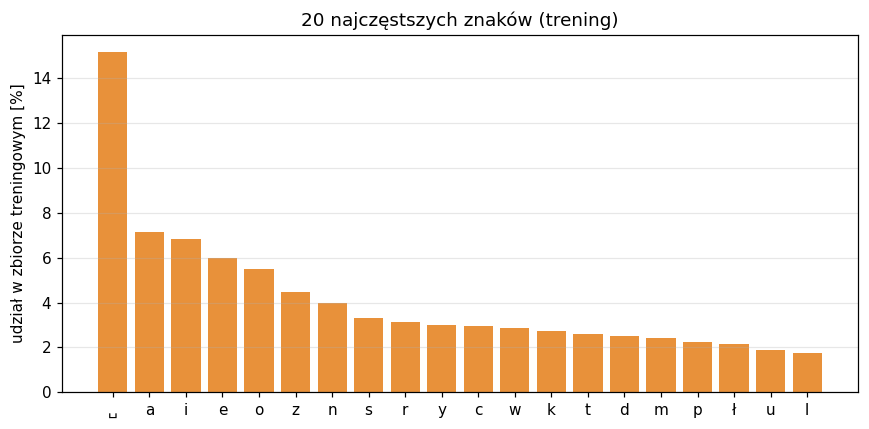

In [12]:
def etykieta(c):
    return {' ': '␣', '\n': '\\n', UNK: '<unk>'}.get(c, c)

licznik = collections.Counter(czesci['train'])
top = licznik.most_common(20)
for c, k in top[:10]:
    print(f'{etykieta(c):>5}  {k:>8}  {100*k/len(czesci["train"]):5.2f} %')

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([etykieta(c) for c, _ in top], [100*k/len(czesci['train']) for _, k in top], color='#e8913a')
ax.set_ylabel('udział w zbiorze treningowym [%]'); ax.set_title('20 najczęstszych znaków (trening)')
ax.grid(axis='y', alpha=.3); plt.tight_layout(); plt.savefig('fig_top_znaki.png'); plt.show()

Liczba słów w treningu: 93281 | różnych: 19584 | średnia długość słowa: 5.27
Top 15: [('i', 2849), ('się', 2560), ('w', 1984), ('nie', 1712), ('na', 1698), ('z', 1475), ('do', 1210), ('że', 1074), ('a', 1061), ('to', 830), ('pan', 691), ('wokulski', 670), ('za', 597), ('o', 573), ('ale', 538)]


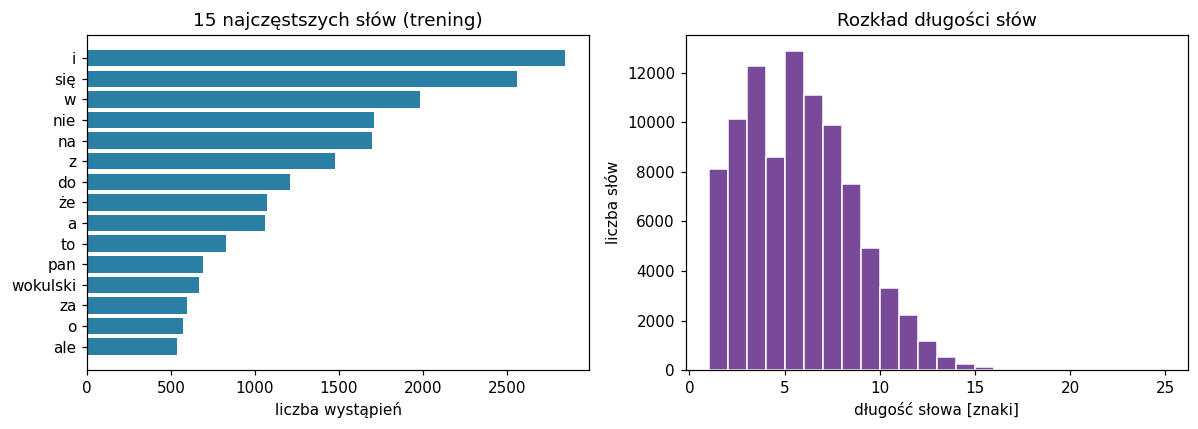

In [13]:
slowa = re.findall(r'\w+', czesci['train'].lower())
cw = collections.Counter(slowa)
top_slowa = cw.most_common(15)
dlugosci = np.array([len(w) for w in slowa])
print('Liczba słów w treningu:', len(slowa), '| różnych:', len(cw), '| średnia długość słowa: %.2f' % dlugosci.mean())
print('Top 15:', top_slowa)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh([w for w, _ in top_slowa][::-1], [k for _, k in top_slowa][::-1], color='#2a7fa5')
ax[0].set_title('15 najczęstszych słów (trening)'); ax[0].set_xlabel('liczba wystąpień')
ax[1].hist(dlugosci, bins=range(1, int(dlugosci.max()) + 2), color='#7a4a9a', edgecolor='white')
ax[1].set_title('Rozkład długości słów'); ax[1].set_xlabel('długość słowa [znaki]'); ax[1].set_ylabel('liczba słów')
plt.tight_layout(); plt.savefig('fig_slowa.png'); plt.show()